In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()

# If Jupyter is not running from the project folder,
# change this to your actual BharatMarket_AI folder.
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path(
        r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
    )

os.chdir(PROJECT_ROOT)

print("Project directory:", PROJECT_ROOT)
print("Project directory exists:", PROJECT_ROOT.exists())

Project directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Project directory exists: True


In [2]:
INITIAL_CAPITAL = 100000

RISK_PER_TRADE_PCT = 1.0
MAX_DAILY_LOSS_PCT = 2.0

MAX_TRADES_PER_DAY = 3
MAX_POSITION_NOTIONAL_PCT = 33.0

SIGNAL_THRESHOLD_PCT = 0.25

ATR_STOP_MULTIPLIER = 1.5
MIN_REWARD_RISK = 1.5

# Illustrative costs, not an exact Upstox or Indian exchange tariff.
BROKERAGE_PER_SIDE_PCT = 0.03
SLIPPAGE_PER_SIDE_PCT = 0.05

# Total cost is calculated on entry and exit turnover.
COST_PER_SIDE_PCT = (
    BROKERAGE_PER_SIDE_PCT + SLIPPAGE_PER_SIDE_PCT
)

INSTRUMENTS = [
    "NIFTY50",
    "BANKNIFTY",
    "RELIANCE",
    "TCS",
    "HDFCBANK",
    "INFY",
    "ICICIBANK",
    "SBIN",
    "ITC",
    "LT"
]

PREDICTIONS_FILE = (
    PROJECT_ROOT /
    "data" /
    "forecasts" /
    "return_based_walk_forward_predictions.csv"
)

BEST_MODELS_FILE = (
    PROJECT_ROOT /
    "outputs" /
    "reports" /
    "return_based_best_models.csv"
)

FEATURES_DIR = PROJECT_ROOT / "data" / "features"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
REPORT_DIR = OUTPUT_DIR / "reports"
CHART_DIR = OUTPUT_DIR / "charts"
FORECAST_DIR = PROJECT_ROOT / "data" / "forecasts"

for folder in [REPORT_DIR, CHART_DIR, FORECAST_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Backtesting configuration loaded.")

Backtesting configuration loaded.


In [3]:
if not PREDICTIONS_FILE.exists():
    raise FileNotFoundError(
        f"Missing predictions file: {PREDICTIONS_FILE}"
    )

if not BEST_MODELS_FILE.exists():
    raise FileNotFoundError(
        f"Missing best models file: {BEST_MODELS_FILE}"
    )

predictions = pd.read_csv(PREDICTIONS_FILE)
best_models = pd.read_csv(BEST_MODELS_FILE)

print("Walk-forward predictions:", predictions.shape)
print("Best model records:", best_models.shape)

print("\nPrediction columns:")
print(predictions.columns.tolist())

print("\nBest model columns:")
print(best_models.columns.tolist())

display(predictions.head())
display(best_models.head())

Walk-forward predictions: (10390, 10)
Best model records: (10, 10)

Prediction columns:
['Instrument', 'Fold', 'Date', 'Model', 'Current_Close', 'Actual_Next_Return_Pct', 'Predicted_Next_Return_Pct', 'Actual_Next_Close', 'Predicted_Next_Close', 'Prediction_Error']

Best model columns:
['Instrument', 'Best_Model', 'Mean_Return_MAE', 'Mean_Return_RMSE', 'Mean_Price_MAE', 'Mean_Price_RMSE', 'Mean_Price_R2', 'Mean_Directional_Accuracy', 'Mean_Directional_Coverage', 'Std_Price_RMSE']


,Instrument,Fold,Date,Model,Current_Close,Actual_Next_Return_Pct,Predicted_Next_Return_Pct,Actual_Next_Close,Predicted_Next_Close,Prediction_Error
0,NIFTY50,1,2026-01-19,Linear Regression,25585.500000,-1.379688,-0.287026,25232.500000,25512.062951,-279.562951
1,NIFTY50,1,2026-01-20,Linear Regression,25232.500000,-0.297236,0.296214,25157.500000,25307.242299,-149.742299
2,NIFTY50,1,2026-01-21,Linear Regression,25157.500000,0.526286,0.313782,25289.900391,25236.439626,53.460764
3,NIFTY50,1,2026-01-22,Linear Regression,25289.900391,-0.953938,0.012699,25048.650391,25293.111913,-244.461522
4,NIFTY50,1,2026-01-23,Linear Regression,25048.650391,0.506015,0.505831,25175.400391,25175.354199,0.046191


,Instrument,Best_Model,Mean_Return_MAE,Mean_Return_RMSE,Mean_Price_MAE,Mean_Price_RMSE,Mean_Price_R2,Mean_Directional_Accuracy,Mean_Directional_Coverage,Std_Price_RMSE
0,BANKNIFTY,Zero Return Baseline,0.904039,1.176572,511.130521,664.688814,0.675160,45.420168,0.0,226.332996
1,HDFCBANK,Gradient Boosting,1.215628,1.545031,9.529327,12.156736,0.722470,42.927171,100.0,3.166703
2,ICICIBANK,Zero Return Baseline,1.068465,1.366950,14.525811,18.621060,0.799852,45.658263,0.0,4.889060
3,INFY,Zero Return Baseline,1.568403,2.084895,18.585570,24.959613,0.823525,46.120448,0.0,3.849441
4,ITC,Linear Regression,1.031992,1.360808,2.981302,3.917680,0.648470,53.375350,100.0,0.786501


In [4]:
def find_column(df, candidates):
    normalized = {
        str(col).strip().lower().replace(" ", "_"): col
        for col in df.columns
    }

    for candidate in candidates:
        key = candidate.strip().lower().replace(" ", "_")
        if key in normalized:
            return normalized[key]

    return None


instrument_col = find_column(
    best_models, ["Instrument", "Symbol"]
)

best_model_col = find_column(
    best_models,
    ["Best_Model", "Selected_Model", "Best Model", "Model"]
)

if instrument_col is None or best_model_col is None:
    raise ValueError(
        "Could not identify instrument or best-model columns "
        "in return_based_best_models.csv"
    )

required_prediction_columns = [
    "Instrument",
    "Fold",
    "Date",
    "Model",
    "Predicted_Next_Return_Pct"
]

missing = [
    col for col in required_prediction_columns
    if col not in predictions.columns
]

if missing:
    raise ValueError(
        f"Missing prediction columns: {missing}"
    )

predictions["Date"] = pd.to_datetime(
    predictions["Date"], errors="coerce"
)

predictions["Instrument"] = (
    predictions["Instrument"].astype(str).str.upper().str.strip()
)

predictions["Model"] = (
    predictions["Model"].astype(str).str.strip()
)

best_models["Instrument"] = (
    best_models[instrument_col].astype(str).str.upper().str.strip()
)

best_models["Selected_Model"] = (
    best_models[best_model_col].astype(str).str.strip()
)

selected_predictions = []

for _, row in best_models.iterrows():

    symbol = row["Instrument"]
    selected_model = row["Selected_Model"]

    instrument_data = predictions[
        predictions["Instrument"] == symbol
    ].copy()

    if instrument_data.empty:
        print("No prediction rows found for:", symbol)
        continue

    if "Zero Return Baseline" in selected_model:

        base = instrument_data[
            ["Instrument", "Fold", "Date"]
        ].drop_duplicates().copy()

        base["Model"] = "Zero Return Baseline"
        base["Predicted_Next_Return_Pct"] = 0.0

        selected_predictions.append(base)

    else:

        model_data = instrument_data[
            instrument_data["Model"] == selected_model
        ].copy()

        if model_data.empty:
            print(
                f"Selected model not found for {symbol}: "
                f"{selected_model}"
            )
            continue

        selected_predictions.append(
            model_data[
                [
                    "Instrument",
                    "Fold",
                    "Date",
                    "Model",
                    "Predicted_Next_Return_Pct"
                ]
            ]
        )

if not selected_predictions:
    raise ValueError("No selected-model predictions were generated.")

selected_predictions = pd.concat(
    selected_predictions,
    ignore_index=True
)

selected_predictions = selected_predictions.drop_duplicates(
    subset=["Instrument", "Fold", "Date"]
)

selected_predictions["Predicted_Next_Return_Pct"] = pd.to_numeric(
    selected_predictions["Predicted_Next_Return_Pct"],
    errors="coerce"
)

selected_predictions = selected_predictions.dropna(
    subset=["Date", "Predicted_Next_Return_Pct"]
)

print("Selected out-of-sample predictions:", len(selected_predictions))
display(selected_predictions.head())

Selected out-of-sample predictions: 2078


,Instrument,Fold,Date,Model,Predicted_Next_Return_Pct
0,BANKNIFTY,1,2026-01-19,Zero Return Baseline,0.0
1,BANKNIFTY,1,2026-01-20,Zero Return Baseline,0.0
2,BANKNIFTY,1,2026-01-21,Zero Return Baseline,0.0
3,BANKNIFTY,1,2026-01-22,Zero Return Baseline,0.0
4,BANKNIFTY,1,2026-01-23,Zero Return Baseline,0.0


In [5]:
def get_case_insensitive_column(df, candidates):
    lookup = {
        str(col).strip().lower().replace(" ", "").replace("_", ""): col
        for col in df.columns
    }

    for candidate in candidates:
        key = candidate.strip().lower().replace(" ", "").replace("_", "")
        if key in lookup:
            return lookup[key]

    return None


def load_instrument_features(symbol):

    file_path = FEATURES_DIR / f"{symbol}_features_full.csv"

    if not file_path.exists():
        raise FileNotFoundError(
            f"Feature file not found for {symbol}: {file_path}"
        )

    df = pd.read_csv(file_path)

    date_col = get_case_insensitive_column(
        df, ["date", "datetime"]
    )

    open_col = get_case_insensitive_column(df, ["open"])
    high_col = get_case_insensitive_column(df, ["high"])
    low_col = get_case_insensitive_column(df, ["low"])
    close_col = get_case_insensitive_column(df, ["close"])

    rsi_col = get_case_insensitive_column(
        df, ["RSI14", "RSI_14", "RSI"]
    )

    macd_col = get_case_insensitive_column(
        df, ["MACD"]
    )

    macd_signal_col = get_case_insensitive_column(
        df, ["MACD_Signal", "MACDSignal", "Signal_Line"]
    )

    atr_col = get_case_insensitive_column(
        df, ["ATR14", "ATR_14", "ATR"]
    )

    required = {
        "date": date_col,
        "open": open_col,
        "high": high_col,
        "low": low_col,
        "close": close_col,
        "RSI": rsi_col,
        "MACD": macd_col,
        "MACD signal": macd_signal_col,
        "ATR": atr_col
    }

    missing = [name for name, col in required.items() if col is None]

    if missing:
        raise ValueError(
            f"{symbol}: missing required feature columns: {missing}. "
            f"Available columns: {df.columns.tolist()}"
        )

    df = df.rename(columns={
        date_col: "Date",
        open_col: "Open",
        high_col: "High",
        low_col: "Low",
        close_col: "Close",
        rsi_col: "RSI",
        macd_col: "MACD",
        macd_signal_col: "MACD_Signal",
        atr_col: "ATR"
    })

    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    numeric_cols = [
        "Open", "High", "Low", "Close",
        "RSI", "MACD", "MACD_Signal", "ATR"
    ]

    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = (
        df.dropna(subset=["Date"])
        .sort_values("Date")
        .drop_duplicates(subset=["Date"], keep="last")
        .reset_index(drop=True)
    )

    # Shift OHLC by one row to get the next available trading session.
    df["Next_Date"] = df["Date"].shift(-1)
    df["Next_Open"] = df["Open"].shift(-1)
    df["Next_High"] = df["High"].shift(-1)
    df["Next_Low"] = df["Low"].shift(-1)
    df["Next_Close"] = df["Close"].shift(-1)

    return df[
        [
            "Date", "Close", "RSI", "MACD", "MACD_Signal", "ATR",
            "Next_Date", "Next_Open", "Next_High",
            "Next_Low", "Next_Close"
        ]
    ]


feature_frames = []

for symbol in INSTRUMENTS:

    try:
        feature_df = load_instrument_features(symbol)
        feature_df["Instrument"] = symbol
        feature_frames.append(feature_df)

        print(f"{symbol}: {len(feature_df)} feature rows loaded")

    except Exception as error:
        print(f"{symbol}: ERROR — {error}")

if not feature_frames:
    raise ValueError("No instrument feature files could be loaded.")

all_features = pd.concat(
    feature_frames,
    ignore_index=True
)

print("\nTotal feature records:", len(all_features))

NIFTY50: 1236 feature rows loaded
BANKNIFTY: 1235 feature rows loaded
RELIANCE: 1237 feature rows loaded
TCS: 1237 feature rows loaded
HDFCBANK: 1237 feature rows loaded
INFY: 1237 feature rows loaded
ICICIBANK: 1237 feature rows loaded
SBIN: 1237 feature rows loaded
ITC: 1237 feature rows loaded
LT: 1237 feature rows loaded

Total feature records: 12367


In [6]:
backtest_data = selected_predictions.merge(
    all_features,
    on=["Instrument", "Date"],
    how="inner"
)

backtest_data = backtest_data.dropna(
    subset=[
        "Next_Date",
        "Next_Open",
        "Next_High",
        "Next_Low",
        "Next_Close",
        "ATR",
        "RSI",
        "MACD",
        "MACD_Signal"
    ]
).copy()

backtest_data = backtest_data[
    (backtest_data["Next_Open"] > 0) &
    (backtest_data["Next_High"] > 0) &
    (backtest_data["Next_Low"] > 0) &
    (backtest_data["Next_Close"] > 0) &
    (backtest_data["ATR"] > 0)
]

backtest_data = backtest_data.sort_values(
    ["Next_Date", "Instrument"]
).reset_index(drop=True)

print("Matched backtest observations:", len(backtest_data))
print(
    "Backtest period:",
    backtest_data["Next_Date"].min(),
    "to",
    backtest_data["Next_Date"].max()
)

display(backtest_data.head())

Matched backtest observations: 2078
Backtest period: 2026-01-19 00:00:00 to 2026-11-23 00:00:00


,Instrument,Fold,Date,Model,Predicted_Next_Return_Pct,Close,RSI,MACD,MACD_Signal,ATR,Next_Date,Next_Open,Next_High,Next_Low,Next_Close
0,HDFCBANK,1,2026-01-16,Gradient Boosting,-0.421141,931.099976,27.808801,-17.256431,-12.316564,13.528251,2026-01-19,935.900024,936.150024,919.500000,927.900024
1,ICICIBANK,1,2026-01-16,Zero Return Baseline,0.000000,1410.800049,56.977197,14.674974,10.222291,20.840364,2026-01-19,1399.900024,1400.000000,1360.000000,1380.599976
2,INFY,1,2026-01-16,Zero Return Baseline,0.000000,1689.800049,65.872631,8.546128,9.561727,31.422899,2026-01-19,1685.000000,1685.000000,1666.500000,1681.199951
3,ITC,1,2026-01-16,Linear Regression,-0.487423,329.200012,12.192329,-18.643231,-15.781621,6.388978,2026-01-19,330.000000,334.649994,327.299988,333.200012
4,LT,1,2026-01-16,Zero Return Baseline,0.000000,3856.399902,29.236150,-36.606703,-3.842372,67.875991,2026-01-19,3820.000000,3878.399902,3808.500000,3869.800049


In [7]:
def generate_signal(row):

    predicted_return = row["Predicted_Next_Return_Pct"]
    rsi = row["RSI"]
    macd = row["MACD"]
    macd_signal = row["MACD_Signal"]

    if (
        predicted_return >= SIGNAL_THRESHOLD_PCT
        and rsi < 70
        and macd > macd_signal
    ):
        return "BUY"

    elif (
        predicted_return <= -SIGNAL_THRESHOLD_PCT
        and rsi > 30
        and macd < macd_signal
    ):
        return "SELL"

    return "HOLD"


backtest_data["Signal"] = backtest_data.apply(
    generate_signal,
    axis=1
)

print("Signal distribution:")
display(
    backtest_data["Signal"].value_counts().rename_axis("Signal").to_frame("Count")
)

print("\nSignals by instrument:")
display(
    pd.crosstab(
        backtest_data["Instrument"],
        backtest_data["Signal"]
    )
)

Signal distribution:


,Count
Signal,
HOLD,1984
BUY,63
SELL,31



Signals by instrument:


Signal,BUY,HOLD,SELL
Instrument,,,
BANKNIFTY,0,207,0
HDFCBANK,9,193,6
ICICIBANK,0,208,0
INFY,0,208,0
ITC,14,171,23
LT,0,208,0
NIFTY50,0,207,0
RELIANCE,40,166,2
SBIN,0,208,0


In [8]:
def simulate_trade(row, equity):

    signal = row["Signal"]

    if signal == "HOLD":
        return None

    entry = float(row["Next_Open"])
    high = float(row["Next_High"])
    low = float(row["Next_Low"])
    close = float(row["Next_Close"])
    atr = float(row["ATR"])

    if min(entry, atr) <= 0:
        return None

    risk_budget = equity * RISK_PER_TRADE_PCT / 100

    stop_distance = atr * ATR_STOP_MULTIPLIER
    target_distance = stop_distance * MIN_REWARD_RISK

    if signal == "BUY":

        direction = 1
        stop = entry - stop_distance
        target = entry + target_distance

        stop_hit = low <= stop
        target_hit = high >= target

    else:

        direction = -1
        stop = entry + stop_distance
        target = entry - target_distance

        stop_hit = high >= stop
        target_hit = low <= target

    risk_per_unit = abs(entry - stop)

    quantity_by_risk = int(risk_budget // risk_per_unit)

    max_notional = equity * MAX_POSITION_NOTIONAL_PCT / 100
    quantity_by_notional = int(max_notional // entry)

    quantity = min(quantity_by_risk, quantity_by_notional)

    if quantity <= 0:
        return None

    # Conservative execution:
    # if stop and target are both touched, assume stop first.
    if stop_hit:

        if signal == "BUY" and row["Next_Open"] < stop:
            exit_price = entry if row["Next_Open"] >= entry else row["Next_Open"]
        elif signal == "SELL" and row["Next_Open"] > stop:
            exit_price = row["Next_Open"]
        else:
            exit_price = stop

        exit_reason = "STOP_LOSS"

    elif target_hit:

        if signal == "BUY" and row["Next_Open"] > target:
            exit_price = row["Next_Open"]
        elif signal == "SELL" and row["Next_Open"] < target:
            exit_price = row["Next_Open"]
        else:
            exit_price = target

        exit_reason = "TARGET"

    else:
        exit_price = close
        exit_reason = "SESSION_CLOSE"

    gross_pnl = direction * (exit_price - entry) * quantity

    entry_turnover = entry * quantity
    exit_turnover = exit_price * quantity

    total_cost = (
        entry_turnover + exit_turnover
    ) * COST_PER_SIDE_PCT / 100

    net_pnl = gross_pnl - total_cost

    return {
        "Instrument": row["Instrument"],
        "Model": row["Model"],
        "Signal_Date": row["Date"],
        "Trade_Date": row["Next_Date"],
        "Signal": signal,
        "Predicted_Return_Pct": row["Predicted_Next_Return_Pct"],
        "Entry_Price": entry,
        "Stop_Loss": stop,
        "Target": target,
        "Exit_Price": exit_price,
        "Exit_Reason": exit_reason,
        "Quantity": quantity,
        "Risk_Budget": risk_budget,
        "Gross_PnL": gross_pnl,
        "Transaction_Cost": total_cost,
        "Net_PnL": net_pnl,
        "Return_on_Notional_Pct": (
            net_pnl / entry_turnover * 100
            if entry_turnover > 0 else 0
        )
    }


print("Trade simulation function is ready.")

Trade simulation function is ready.


In [9]:
all_trades = []
equity = float(INITIAL_CAPITAL)

daily_records = []

trading_dates = sorted(
    backtest_data["Next_Date"].dropna().unique()
)

for trade_date in trading_dates:

    starting_day_equity = equity
    daily_pnl = 0.0
    trades_today = 0

    day_data = backtest_data[
        backtest_data["Next_Date"] == trade_date
    ].copy()

    # Prioritise the strongest forecast signals.
    day_data["Signal_Strength"] = (
        day_data["Predicted_Next_Return_Pct"].abs()
    )

    day_data = day_data[
        day_data["Signal"] != "HOLD"
    ].sort_values(
        "Signal_Strength",
        ascending=False
    )

    for _, row in day_data.iterrows():

        if trades_today >= MAX_TRADES_PER_DAY:
            break

        daily_loss_limit = (
            starting_day_equity * MAX_DAILY_LOSS_PCT / 100
        )

        if daily_pnl <= -daily_loss_limit:
            break

        trade = simulate_trade(row, equity)

        if trade is None:
            continue

        trade["Equity_Before_Trade"] = equity

        equity += trade["Net_PnL"]
        daily_pnl += trade["Net_PnL"]

        trade["Equity_After_Trade"] = equity

        all_trades.append(trade)
        trades_today += 1

    daily_records.append({
        "Date": pd.Timestamp(trade_date),
        "Starting_Equity": starting_day_equity,
        "Daily_PnL": daily_pnl,
        "Trades": trades_today,
        "Ending_Equity": equity
    })

trades_df = pd.DataFrame(all_trades)
daily_df = pd.DataFrame(daily_records)

print("Backtesting completed.")
print("Total trades:", len(trades_df))
print("Trading sessions:", len(daily_df))
print("Final equity: ₹{:,.2f}".format(equity))

if not trades_df.empty:
    display(trades_df.head(10))
else:
    print("No qualifying trades were generated.")

Backtesting completed.
Total trades: 94
Trading sessions: 208
Final equity: ₹103,876.62


,Instrument,Model,Signal_Date,Trade_Date,Signal,Predicted_Return_Pct,Entry_Price,Stop_Loss,Target,Exit_Price,Exit_Reason,Quantity,Risk_Budget,Gross_PnL,Transaction_Cost,Net_PnL,Return_on_Notional_Pct,Equity_Before_Trade,Equity_After_Trade
0,HDFCBANK,Gradient Boosting,2026-01-27,2026-01-28,SELL,-0.301642,932.500000,955.233725,898.399413,932.700012,SESSION_CLOSE,35,1000.000000,-7.000427,52.225600,-59.226028,-0.181466,100000.000000,99940.773972
1,RELIANCE,Gradient Boosting,2026-01-28,2026-01-29,SELL,-0.277891,1402.900024,1443.983839,1341.274302,1391.000000,SESSION_CLOSE,23,999.407740,273.700562,51.407760,222.292801,0.688923,99940.773972,100163.066773
2,ITC,Linear Regression,2026-02-02,2026-02-03,BUY,2.506678,321.200012,310.156837,337.764774,316.649994,SESSION_CLOSE,90,1001.630668,-409.501648,45.925200,-455.426848,-1.575435,100163.066773,99707.639925
3,RELIANCE,Gradient Boosting,2026-02-02,2026-02-03,SELL,-0.328801,1473.900024,1516.897985,1409.403083,1437.099976,SESSION_CLOSE,22,997.076399,809.601074,51.233600,758.367474,2.338778,99707.639925,100466.007399
4,ITC,Linear Regression,2026-02-04,2026-02-05,BUY,0.661441,313.950012,302.551945,331.047113,310.200012,SESSION_CLOSE,88,1004.660074,-330.000000,43.940162,-373.940162,-1.353502,100466.007399,100092.067238
5,RELIANCE,Gradient Boosting,2026-02-05,2026-02-06,BUY,0.405406,1441.500000,1392.884814,1514.422779,1450.800049,SESSION_CLOSE,20,1000.920672,186.000977,46.276801,139.724176,0.484649,100092.067238,100231.791413
6,RELIANCE,Gradient Boosting,2026-02-06,2026-02-09,BUY,0.267086,1458.000000,1410.789465,1528.815803,1461.599976,SESSION_CLOSE,21,1002.317914,75.599487,49.049280,26.550208,0.086714,100231.791413,100258.341621
7,ITC,Linear Regression,2026-02-09,2026-02-10,BUY,0.385423,323.000000,310.629685,341.555473,321.399994,SESSION_CLOSE,81,1002.583416,-129.600494,41.757120,-171.357614,-0.654962,100258.341621,100086.984007
8,HDFCBANK,Gradient Boosting,2026-02-16,2026-02-17,SELL,-0.371440,923.000000,948.952308,884.071539,925.700012,SESSION_CLOSE,35,1000.869840,-94.500427,51.763600,-146.264028,-0.452760,100086.984007,99940.719980
9,ITC,Linear Regression,2026-02-27,2026-03-02,BUY,0.273122,307.000000,297.221948,321.667078,314.899994,SESSION_CLOSE,102,999.407200,805.799377,50.747040,755.052338,2.411229,99940.719980,100695.772317


In [10]:
daily_df["Daily_Return_Pct"] = (
    daily_df["Ending_Equity"] /
    daily_df["Starting_Equity"] - 1
) * 100

daily_df["Cumulative_Peak"] = (
    daily_df["Ending_Equity"].cummax()
)

daily_df["Drawdown_Pct"] = (
    daily_df["Ending_Equity"] /
    daily_df["Cumulative_Peak"] - 1
) * 100

daily_returns = daily_df["Daily_Return_Pct"] / 100

if daily_returns.std(ddof=1) > 0:
    sharpe_ratio = (
        daily_returns.mean() /
        daily_returns.std(ddof=1)
    ) * np.sqrt(252)
else:
    sharpe_ratio = np.nan

if not trades_df.empty:

    winners = trades_df[trades_df["Net_PnL"] > 0]
    losers = trades_df[trades_df["Net_PnL"] < 0]

    win_rate = len(winners) / len(trades_df) * 100

    gross_profit = winners["Net_PnL"].sum()
    gross_loss = abs(losers["Net_PnL"].sum())

    profit_factor = (
        gross_profit / gross_loss
        if gross_loss > 0 else np.inf
    )

    average_trade = trades_df["Net_PnL"].mean()

    best_trade = trades_df["Net_PnL"].max()
    worst_trade = trades_df["Net_PnL"].min()

else:

    win_rate = 0
    gross_profit = 0
    gross_loss = 0
    profit_factor = np.nan
    average_trade = 0
    best_trade = 0
    worst_trade = 0

initial_equity = INITIAL_CAPITAL
final_equity = (
    daily_df["Ending_Equity"].iloc[-1]
    if not daily_df.empty else INITIAL_CAPITAL
)

total_profit = final_equity - initial_equity

total_return_pct = (
    total_profit / initial_equity
) * 100

maximum_drawdown = (
    daily_df["Drawdown_Pct"].min()
    if not daily_df.empty else 0
)

performance_summary = pd.DataFrame([{
    "Initial_Capital": initial_equity,
    "Final_Capital": final_equity,
    "Net_Profit": total_profit,
    "Total_Return_Pct": total_return_pct,
    "Total_Trades": len(trades_df),
    "Winning_Trades": (
        int((trades_df["Net_PnL"] > 0).sum())
        if not trades_df.empty else 0
    ),
    "Losing_Trades": (
        int((trades_df["Net_PnL"] < 0).sum())
        if not trades_df.empty else 0
    ),
    "Win_Rate_Pct": win_rate,
    "Gross_Profit": gross_profit,
    "Gross_Loss": gross_loss,
    "Profit_Factor": profit_factor,
    "Average_Trade_PnL": average_trade,
    "Best_Trade": best_trade,
    "Worst_Trade": worst_trade,
    "Maximum_Drawdown_Pct": maximum_drawdown,
    "Sharpe_Ratio": sharpe_ratio
}])

display(performance_summary.T.rename(columns={0: "Value"}))

,Value
Initial_Capital,100000.000000
Final_Capital,103876.623670
Net_Profit,3876.623670
Total_Return_Pct,3.876624
Total_Trades,94.000000
Winning_Trades,47.000000
Losing_Trades,47.000000
Win_Rate_Pct,50.000000
Gross_Profit,15233.900792
Gross_Loss,11357.277123


In [11]:
if not trades_df.empty:

    instrument_performance = (
        trades_df.groupby("Instrument")
        .agg(
            Trades=("Net_PnL", "count"),
            Net_Profit=("Net_PnL", "sum"),
            Average_Trade=("Net_PnL", "mean"),
            Gross_Profit=(
                "Net_PnL",
                lambda x: x[x > 0].sum()
            ),
            Gross_Loss=(
                "Net_PnL",
                lambda x: abs(x[x < 0].sum())
            )
        )
        .reset_index()
    )

    instrument_performance["Win_Rate_Pct"] = (
        trades_df.assign(
            Is_Winner=trades_df["Net_PnL"] > 0
        )
        .groupby("Instrument")["Is_Winner"]
        .mean()
        .values * 100
    )

    instrument_performance["Profit_Factor"] = (
        instrument_performance["Gross_Profit"] /
        instrument_performance["Gross_Loss"].replace(0, np.nan)
    )

    instrument_performance = instrument_performance.sort_values(
        "Net_Profit",
        ascending=False
    )

else:

    instrument_performance = pd.DataFrame(
        columns=[
            "Instrument", "Trades", "Net_Profit",
            "Average_Trade", "Gross_Profit",
            "Gross_Loss", "Win_Rate_Pct", "Profit_Factor"
        ]
    )

display(instrument_performance)

,Instrument,Trades,Net_Profit,Average_Trade,Gross_Profit,Gross_Loss,Win_Rate_Pct,Profit_Factor
2,RELIANCE,42,3239.656145,77.134670,8431.516902,5191.860757,54.761905,1.623987
1,ITC,37,601.864666,16.266613,4866.426566,4264.561900,45.945946,1.141132
0,HDFCBANK,15,35.102859,2.340191,1935.957324,1900.854465,46.666667,1.018467


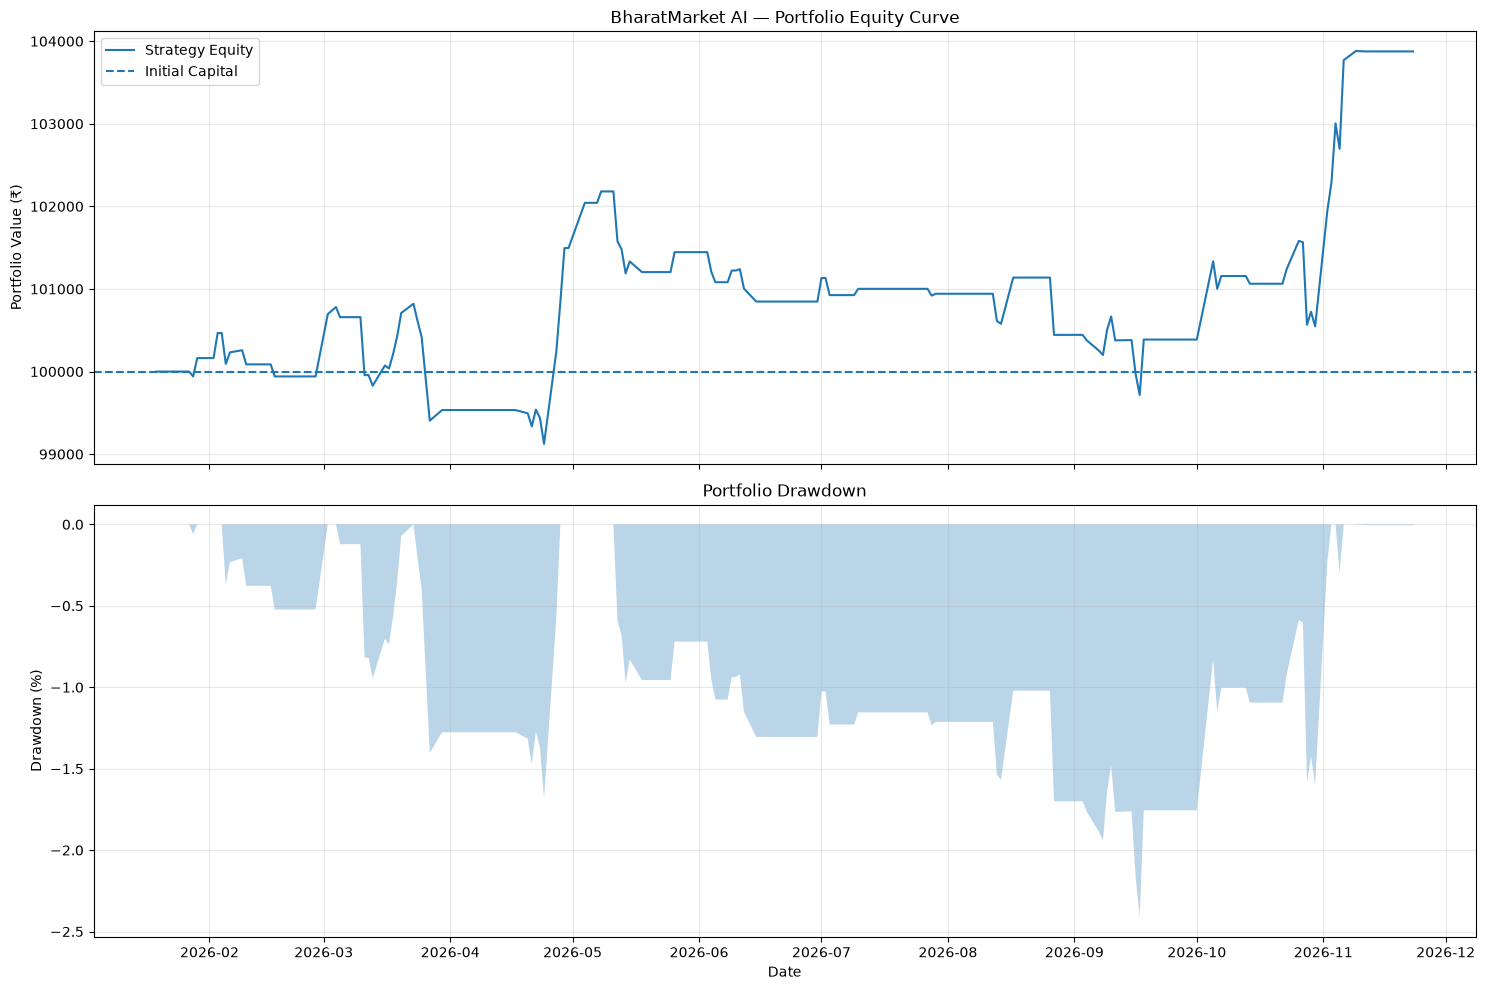

In [12]:
if not daily_df.empty:

    fig, axes = plt.subplots(
        2, 1,
        figsize=(15, 10),
        sharex=True
    )

    axes[0].plot(
        daily_df["Date"],
        daily_df["Ending_Equity"],
        label="Strategy Equity"
    )

    axes[0].axhline(
        INITIAL_CAPITAL,
        linestyle="--",
        label="Initial Capital"
    )

    axes[0].set_title("BharatMarket AI — Portfolio Equity Curve")
    axes[0].set_ylabel("Portfolio Value (₹)")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].fill_between(
        daily_df["Date"],
        daily_df["Drawdown_Pct"],
        0,
        alpha=0.3
    )

    axes[1].set_title("Portfolio Drawdown")
    axes[1].set_ylabel("Drawdown (%)")
    axes[1].set_xlabel("Date")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "backtest_equity_and_drawdown.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("No daily equity data available for plotting.")

In [13]:
benchmark_file = FEATURES_DIR / "NIFTY50_features_full.csv"

benchmark_return_pct = np.nan
benchmark_start = np.nan
benchmark_end = np.nan

if benchmark_file.exists() and not daily_df.empty:

    benchmark = pd.read_csv(benchmark_file)

    date_col = get_case_insensitive_column(
        benchmark, ["date", "datetime"]
    )
    close_col = get_case_insensitive_column(
        benchmark, ["close"]
    )

    if date_col and close_col:

        benchmark = benchmark.rename(columns={
            date_col: "Date",
            close_col: "Close"
        })

        benchmark["Date"] = pd.to_datetime(
            benchmark["Date"], errors="coerce"
        )

        benchmark["Close"] = pd.to_numeric(
            benchmark["Close"], errors="coerce"
        )

        benchmark = benchmark.dropna(
            subset=["Date", "Close"]
        ).sort_values("Date")

        start_date = daily_df["Date"].min()
        end_date = daily_df["Date"].max()

        benchmark_period = benchmark[
            (benchmark["Date"] >= start_date) &
            (benchmark["Date"] <= end_date)
        ]

        if len(benchmark_period) >= 2:

            benchmark_start = benchmark_period["Close"].iloc[0]
            benchmark_end = benchmark_period["Close"].iloc[-1]

            benchmark_return_pct = (
                benchmark_end / benchmark_start - 1
            ) * 100

benchmark_comparison = pd.DataFrame([
    {
        "Strategy": "BharatMarket AI",
        "Return_Pct": total_return_pct
    },
    {
        "Strategy": "NIFTY 50 Buy and Hold",
        "Return_Pct": benchmark_return_pct
    }
])

print("Benchmark comparison:")
display(benchmark_comparison)

# Monthly portfolio returns
if not daily_df.empty:

    monthly_df = daily_df.copy()

    monthly_df["Month"] = (
        monthly_df["Date"].dt.to_period("M").astype(str)
    )

    monthly_returns = (
        monthly_df.groupby("Month")
        .agg(
            Starting_Equity=("Starting_Equity", "first"),
            Ending_Equity=("Ending_Equity", "last"),
            Net_PnL=("Daily_PnL", "sum"),
            Trades=("Trades", "sum")
        )
        .reset_index()
    )

    monthly_returns["Monthly_Return_Pct"] = (
        monthly_returns["Ending_Equity"] /
        monthly_returns["Starting_Equity"] - 1
    ) * 100

else:
    monthly_returns = pd.DataFrame()

display(monthly_returns.head(12))

Benchmark comparison:


,Strategy,Return_Pct
0,BharatMarket AI,3.876624
1,NIFTY 50 Buy and Hold,-0.921810


,Month,Starting_Equity,Ending_Equity,Net_PnL,Trades,Monthly_Return_Pct
0,2026-01,100000.000000,100163.066773,163.066773,2,0.163067
1,2026-02,100163.066773,99940.719980,-222.346794,7,-0.221985
2,2026-03,99940.719980,99533.834134,-406.885846,18,-0.407127
3,2026-04,99533.834134,101495.268870,1961.434736,8,1.970621
4,2026-05,101495.268870,101445.764901,-49.503969,8,-0.048775
5,2026-06,101445.764901,100847.505015,-598.259886,6,-0.589734
6,2026-07,100847.505015,100941.997899,94.492884,6,0.093699
7,2026-08,100941.997899,100444.243949,-497.753951,5,-0.493109
8,2026-09,100444.243949,100387.336436,-56.907513,12,-0.056656
9,2026-10,100387.336436,100546.932913,159.596478,12,0.158981


In [14]:
trades_file = REPORT_DIR / "backtest_trade_log.csv"
daily_file = REPORT_DIR / "backtest_daily_portfolio.csv"
performance_file = REPORT_DIR / "backtest_performance_summary.csv"
instrument_file = REPORT_DIR / "backtest_instrument_performance.csv"
monthly_file = REPORT_DIR / "backtest_monthly_returns.csv"
benchmark_file_out = REPORT_DIR / "backtest_benchmark_comparison.csv"
signals_file = REPORT_DIR / "backtest_generated_signals.csv"

if not trades_df.empty:
    trades_df.to_csv(trades_file, index=False)

daily_df.to_csv(daily_file, index=False)
performance_summary.to_csv(performance_file, index=False)
instrument_performance.to_csv(instrument_file, index=False)
monthly_returns.to_csv(monthly_file, index=False)
benchmark_comparison.to_csv(benchmark_file_out, index=False)
backtest_data.to_csv(signals_file, index=False)

print("Backtesting files exported successfully.")

for file in [
    trades_file,
    daily_file,
    performance_file,
    instrument_file,
    monthly_file,
    benchmark_file_out,
    signals_file
]:
    if file.exists():
        print("Saved:", file.relative_to(PROJECT_ROOT))

Backtesting files exported successfully.
Saved: outputs\reports\backtest_trade_log.csv
Saved: outputs\reports\backtest_daily_portfolio.csv
Saved: outputs\reports\backtest_performance_summary.csv
Saved: outputs\reports\backtest_instrument_performance.csv
Saved: outputs\reports\backtest_monthly_returns.csv
Saved: outputs\reports\backtest_benchmark_comparison.csv
Saved: outputs\reports\backtest_generated_signals.csv


In [15]:
print("=" * 65)
print("BHARATMARKET AI — NOTEBOOK 10 BACKTESTING SUMMARY")
print("=" * 65)

print("\nPORTFOLIO")
print("-" * 40)
print(f"Initial Capital:       ₹{INITIAL_CAPITAL:,.2f}")
print(f"Final Capital:         ₹{final_equity:,.2f}")
print(f"Net Profit/Loss:       ₹{total_profit:,.2f}")
print(f"Total Return:          {total_return_pct:.2f}%")

print("\nTRADING PERFORMANCE")
print("-" * 40)
print(f"Total Trades:          {len(trades_df)}")
print(f"Win Rate:              {win_rate:.2f}%")
print(f"Profit Factor:         {profit_factor:.2f}")
print(f"Average Trade P&L:     ₹{average_trade:,.2f}")
print(f"Best Trade:            ₹{best_trade:,.2f}")
print(f"Worst Trade:           ₹{worst_trade:,.2f}")

print("\nRISK PERFORMANCE")
print("-" * 40)
print(f"Maximum Drawdown:      {maximum_drawdown:.2f}%")
print(f"Sharpe Ratio:          {sharpe_ratio:.3f}")

print("\nBENCHMARK")
print("-" * 40)
print(f"NIFTY 50 Return:       {benchmark_return_pct:.2f}%")

print("\nDATA")
print("-" * 40)
print("Instruments configured:", len(INSTRUMENTS))
print("Matched observations:", len(backtest_data))

if not daily_df.empty:
    print("Backtest start:", daily_df["Date"].min().date())
    print("Backtest end:", daily_df["Date"].max().date())

print("\n" + "=" * 65)
print("NOTEBOOK 10 EXECUTION COMPLETED")
print("=" * 65)

BHARATMARKET AI — NOTEBOOK 10 BACKTESTING SUMMARY

PORTFOLIO
----------------------------------------
Initial Capital:       ₹100,000.00
Final Capital:         ₹103,876.62
Net Profit/Loss:       ₹3,876.62
Total Return:          3.88%

TRADING PERFORMANCE
----------------------------------------
Total Trades:          94
Win Rate:              50.00%
Profit Factor:         1.34
Average Trade P&L:     ₹41.24
Best Trade:            ₹1,403.78
Worst Trade:           ₹-1,013.41

RISK PERFORMANCE
----------------------------------------
Maximum Drawdown:      -2.41%
Sharpe Ratio:          1.143

BENCHMARK
----------------------------------------
NIFTY 50 Return:       -0.92%

DATA
----------------------------------------
Instruments configured: 10
Matched observations: 2078
Backtest start: 2026-01-19
Backtest end: 2026-11-23

NOTEBOOK 10 EXECUTION COMPLETED
